# 4단계 탐색적 분석

정규화가 끝난 `tidy_rewards.csv`만 읽어 선데이메이플 정규 보상 패턴을 살펴본다. 기본 분석 대상은 `reward_norm`이 있고 미래 일정이 아닌 행이다.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.viz import save_fig, set_korean_font

set_korean_font()

processed_path = project_root / 'data' / 'processed' / 'tidy_rewards.csv'
figure_dir = project_root / 'outputs' / 'figures'
tidy = pd.read_csv(processed_path, encoding='utf-8')
tidy['date'] = pd.to_datetime(tidy['date'])
analysis = tidy[tidy['reward_norm'].notna() & (~tidy['is_future'])].copy()
analysis['year'] = analysis['date'].dt.year

print('전체 tidy 행 수:', len(tidy))
print('기본 분석 대상 행 수:', len(analysis))
print('분석 대상 날짜 범위:', analysis['date'].min().date().isoformat(), '~', analysis['date'].max().date().isoformat())
print('부분 연도:', '2017년은 3월 시작, 2026년은 6월까지의 공개분만 포함')

전체 tidy 행 수: 1160
기본 분석 대상 행 수: 1118
분석 대상 날짜 범위: 2017-03-12 ~ 2026-06-07
부분 연도: 2017년은 3월 시작, 2026년은 6월까지의 공개분만 포함


## Q1. 보상 카테고리 구성은 9년 동안 어떻게 변했나?

그림 저장 경로: C:\Users\my\Desktop\프로젝트\sunday-maple\outputs\figures\q1_category_share_by_year.png
연도별 카테고리 비중(%):
category    강화    성장  사냥효율  수집기타
year                            
2017      25.4  22.5  38.0  14.1
2018      27.1  27.1  25.0  20.8
2019      39.5  17.3  22.2  21.0
2020      30.1  33.3  17.2  19.4
2021      34.0  28.3  17.0  20.8
2022      29.7  30.6  18.0  21.6
2023      31.3  32.8  19.4  16.4
2024      30.4  36.3  20.5  12.9
2025      35.5  32.2  20.8  11.5
2026      34.7  29.2  16.7  19.4


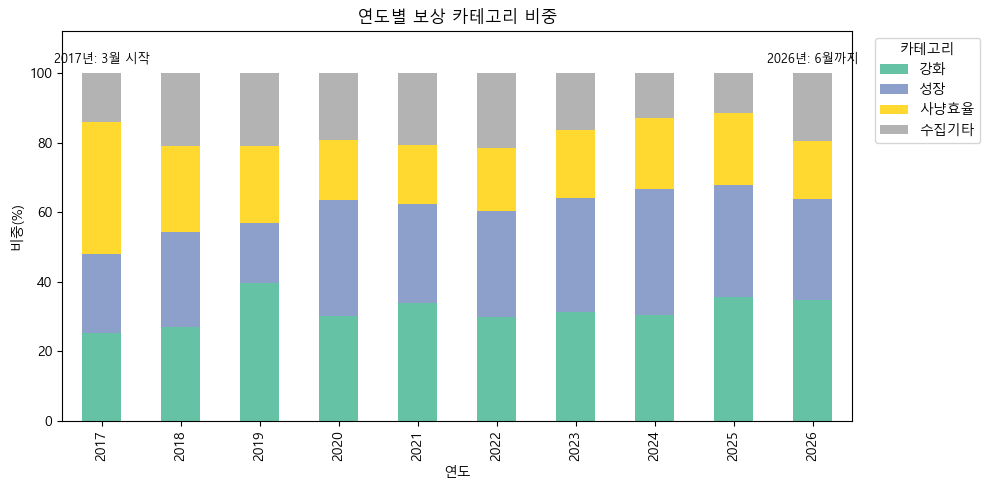

In [2]:
category_order = ['강화', '성장', '사냥효율', '수집기타']
yearly_category = (
    analysis.groupby(['year', 'category'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=category_order, fill_value=0)
)
yearly_category_share = yearly_category.div(yearly_category.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
yearly_category_share.plot(kind='bar', stacked=True, ax=ax, colormap='Set2')
ax.set_title('연도별 보상 카테고리 비중')
ax.set_xlabel('연도')
ax.set_ylabel('비중(%)')
ax.legend(title='카테고리', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.text(0, 103, '2017년: 3월 시작', ha='center', fontsize=9)
ax.text(len(yearly_category_share.index) - 1, 103, '2026년: 6월까지', ha='center', fontsize=9)
ax.set_ylim(0, 112)
fig.tight_layout()
path = save_fig(fig, 'q1_category_share_by_year', figure_dir)
print('그림 저장 경로:', path)
print('연도별 카테고리 비중(%):')
print(yearly_category_share.round(1).to_string())
plt.show()

강화와 사냥효율 계열은 최근 연도에서 존재감이 커졌고, 수집기타는 상대적으로 안정적인 비중을 보인다. 2017년과 2026년은 부분 연도이므로 절대 보상 수보다 비중 중심으로 해석한다.

## Q8. 회차당 보상 수는 시간이 지나며 어떻게 변했나?

그림 저장 경로: C:\Users\my\Desktop\프로젝트\sunday-maple\outputs\figures\q8_rewards_per_session.png
연도별 회차당 보상 수:
      보상 수  고유 회차 수  회차당 보상 수
year                         
2017    71       36     1.972
2018    96       39     2.462
2019    81       44     1.841
2020    93       52     1.788
2021   106       52     2.038
2022   111       52     2.135
2023   134       57     2.351
2024   171       52     3.288
2025   183       52     3.519
2026    72       23     3.130


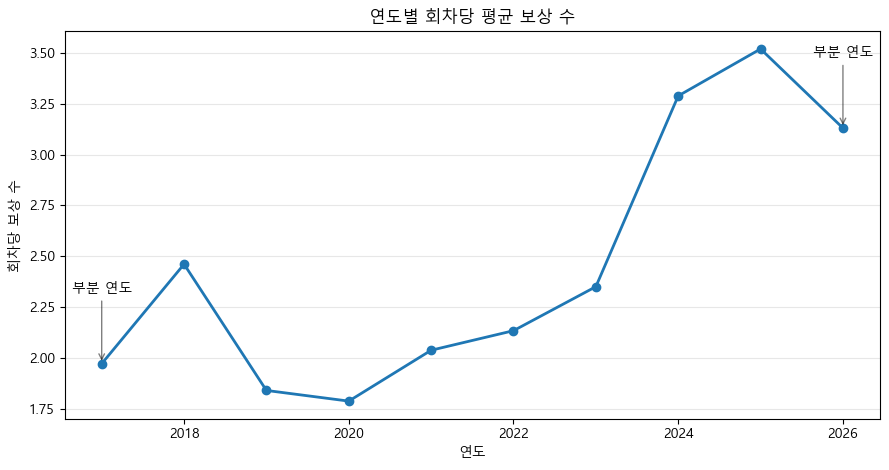

In [3]:
yearly_sessions = analysis.groupby('year')['date'].nunique().rename('고유 회차 수')
yearly_rewards = analysis.groupby('year').size().rename('보상 수')
rewards_per_session = (yearly_rewards / yearly_sessions).rename('회차당 보상 수')
reward_session_summary = pd.concat([yearly_rewards, yearly_sessions, rewards_per_session], axis=1)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(rewards_per_session.index, rewards_per_session.values, marker='o', linewidth=2)
ax.set_title('연도별 회차당 평균 보상 수')
ax.set_xlabel('연도')
ax.set_ylabel('회차당 보상 수')
ax.grid(True, axis='y', alpha=0.3)
ax.annotate('부분 연도', xy=(2017, rewards_per_session.loc[2017]), xytext=(2017, rewards_per_session.loc[2017] + 0.35), ha='center', arrowprops={'arrowstyle': '->', 'alpha': 0.5})
ax.annotate('부분 연도', xy=(2026, rewards_per_session.loc[2026]), xytext=(2026, rewards_per_session.loc[2026] + 0.35), ha='center', arrowprops={'arrowstyle': '->', 'alpha': 0.5})
fig.tight_layout()
path = save_fig(fig, 'q8_rewards_per_session', figure_dir)
print('그림 저장 경로:', path)
print('연도별 회차당 보상 수:')
print(reward_session_summary.round(3).to_string())
plt.show()

회차당 보상 수는 2017년 약 2개에서 2024~2025년 3개 이상으로 올라갔다. 이는 단순한 회차 수 증가가 아니라 한 회차에 함께 제공되는 정규 보상 묶음이 커진 운영 변화로 해석할 수 있다.

## Q2. 어떤 보상이 자주 또는 드물게 재등장하나?

Figure saved: C:\Users\my\Desktop\프로젝트\sunday-maple\outputs\figures\q2_cycle_by_norm.png
Most frequent returning rewards:
reward_norm
프리미엄PC방       7.0
몬스터파크_경험치    21.0
트레져헌터_경험치    24.5
룬_경험치버프      28.0
스타포스_파괴방지    28.0
솔에르다_사냥      28.0
불꽃늑대_경험치     28.0
룬_재등장감소      28.0
콤보킬_경험치      28.0
현상금_경험치      28.0
Rarest returning rewards:
reward_norm
선물_기타지급       469.0
명예의훈장         392.0
데미지스킨_지급      210.0
우르스           210.0
잠재능력_재설정할인    189.0
솔에르다_접속지급     189.0
미라클타임         182.0
유니온프리셋_지급     178.5
헤어타임          175.0
코디타임          175.0


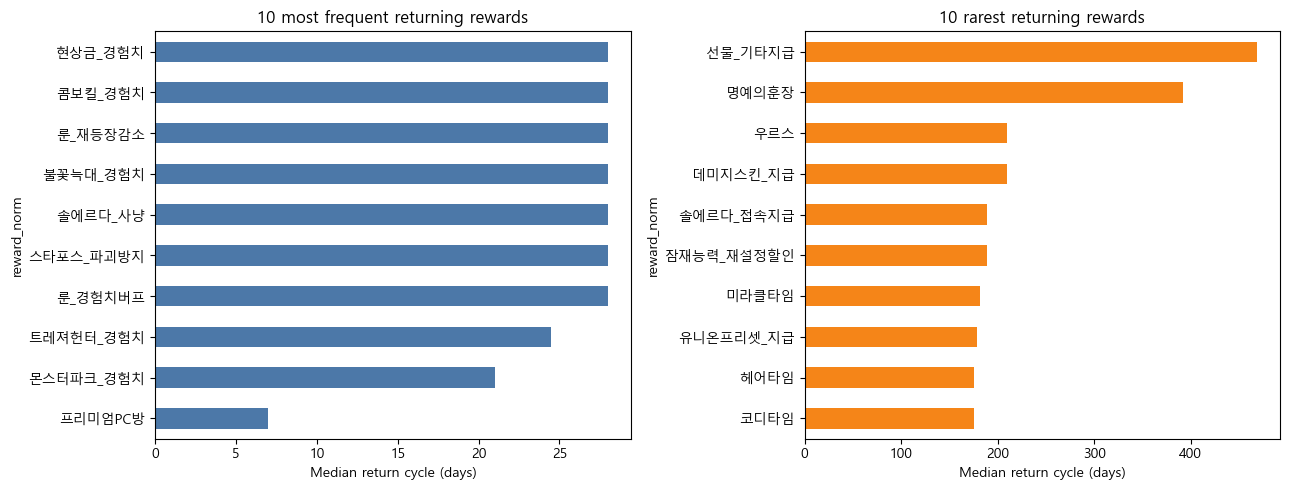

Figure saved: C:\Users\my\Desktop\프로젝트\sunday-maple\outputs\figures\q2_cycle_hist.png
cycle_days summary:
count    1063.0
mean       65.2
std       109.7
min         4.0
25%        28.0
50%        42.0
75%        70.0
max      2030.0
Long gaps over 365 days: 14


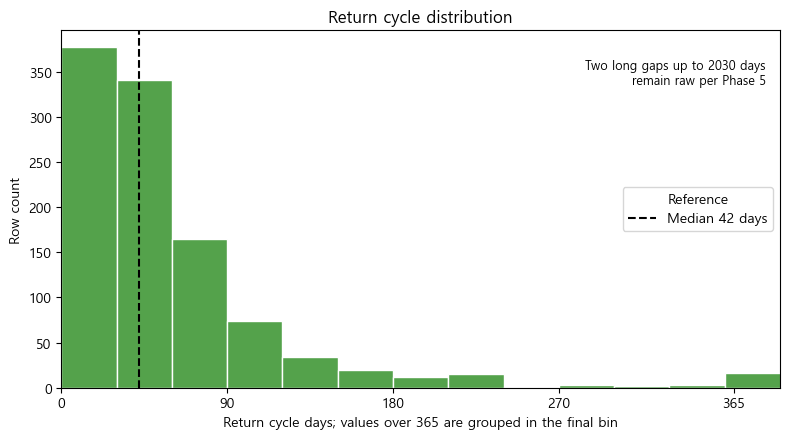

In [4]:
cycle_data = analysis.dropna(subset=['cycle_days']).copy()
cycle_by_norm = cycle_data.groupby('reward_norm')['cycle_days'].median().sort_values()
frequent = cycle_by_norm.head(10).rename('Median cycle days')
rare = cycle_by_norm.tail(10).sort_values(ascending=False).rename('Median cycle days')

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=False)
frequent.sort_values().plot(kind='barh', ax=axes[0], color='#4C78A8')
axes[0].set_title('10 most frequent returning rewards')
axes[0].set_xlabel('Median return cycle (days)')
axes[0].set_ylabel('reward_norm')
rare.sort_values().plot(kind='barh', ax=axes[1], color='#F58518')
axes[1].set_title('10 rarest returning rewards')
axes[1].set_xlabel('Median return cycle (days)')
axes[1].set_ylabel('reward_norm')
fig.tight_layout()
path = save_fig(fig, 'q2_cycle_by_norm', figure_dir)
print('Figure saved:', path)
print('Most frequent returning rewards:')
print(frequent.round(1).to_string())
print('Rarest returning rewards:')
print(rare.round(1).to_string())
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
hist_bins = list(range(0, 366, 30)) + [cycle_data['cycle_days'].max() + 1]
ax.hist(cycle_data['cycle_days'], bins=hist_bins, color='#54A24B', edgecolor='white')
ax.set_title('Return cycle distribution')
ax.set_xlabel('Return cycle days; values over 365 are grouped in the final bin')
ax.set_ylabel('Row count')
ax.axvline(cycle_data['cycle_days'].median(), color='black', linestyle='--', label=f"Median {cycle_data['cycle_days'].median():.0f} days")
ax.set_xlim(0, 390)
ax.set_xticks([0, 90, 180, 270, 365])
ax.text(0.98, 0.92, 'Two long gaps up to 2030 days\nremain raw per Phase 5', transform=ax.transAxes, ha='right', va='top', fontsize=9)
ax.legend(title='Reference')
fig.tight_layout()
path = save_fig(fig, 'q2_cycle_hist', figure_dir)
print('Figure saved:', path)
print('cycle_days summary:')
print(cycle_data['cycle_days'].describe().round(1).to_string())
print('Long gaps over 365 days:', int((cycle_data['cycle_days'] > 365).sum()))
plt.show()


중앙 재등장 주기가 짧은 보상은 운영상 반복적으로 배치되는 핵심 보상에 가깝다. 반대로 중앙 주기가 긴 보상은 특정 시기 운영 방향이나 단종 후 부활의 영향을 크게 받는다.

## Q3. 무엇이 단종되고 무엇이 살아남았나?

Figure saved: C:\Users\my\Desktop\프로젝트\sunday-maple\outputs\figures\q3_discontinued_by_category.png
Unique rewards by category and status:
status    Current  Discontinued
category                       
강화              9             4
성장              5            26
사냥효율            7            20
수집기타            8            21
Reference row-level discontinued/current observations:
is_discontinued
False    807
True     311


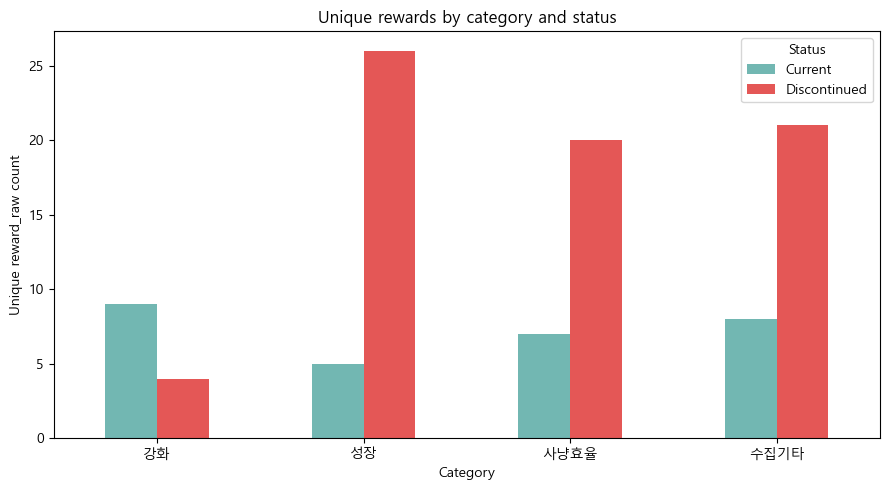

Figure saved: C:\Users\my\Desktop\프로젝트\sunday-maple\outputs\figures\q3_last_seen_year.png
Discontinued reward last-seen-year distribution:
last_seen_year
2017    11
2018    21
2019     9
2020     5
2021     2
2022    10
2023     4
2024     8
2025     1
Unique discontinued reward_raw total: 71


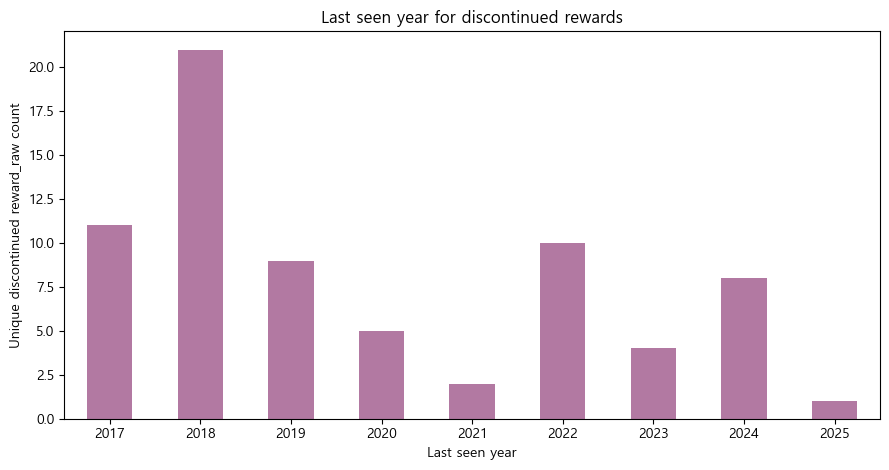

In [5]:
unique_rewards = analysis[['reward_raw', 'reward_norm', 'category', 'is_discontinued']].drop_duplicates()
unique_rewards['status'] = unique_rewards['is_discontinued'].map({True: 'Discontinued', False: 'Current'})
disc_category = (
    unique_rewards.dropna(subset=['is_discontinued'])
    .groupby(['category', 'status'])
    .size()
    .unstack(fill_value=0)
    .reindex(index=category_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(9, 5))
disc_category.plot(kind='bar', ax=ax, color=['#72B7B2', '#E45756'])
ax.set_title('Unique rewards by category and status')
ax.set_xlabel('Category')
ax.set_ylabel('Unique reward_raw count')
ax.legend(title='Status')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
path = save_fig(fig, 'q3_discontinued_by_category', figure_dir)
print('Figure saved:', path)
print('Unique rewards by category and status:')
print(disc_category.to_string())
print('Reference row-level discontinued/current observations:')
print(analysis['is_discontinued'].value_counts(dropna=False).to_string())
plt.show()

last_seen = (
    analysis[analysis['is_discontinued'] == True]
    .groupby('reward_raw')['date']
    .max()
    .dt.year
    .rename('last_seen_year')
)
last_seen_counts = last_seen.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 4.8))
last_seen_counts.plot(kind='bar', ax=ax, color='#B279A2')
ax.set_title('Last seen year for discontinued rewards')
ax.set_xlabel('Last seen year')
ax.set_ylabel('Unique discontinued reward_raw count')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
path = save_fig(fig, 'q3_last_seen_year', figure_dir)
print('Figure saved:', path)
print('Discontinued reward last-seen-year distribution:')
print(last_seen_counts.to_string())
print('Unique discontinued reward_raw total:', int(last_seen_counts.sum()))
plt.show()


단종 보상은 성장·사냥효율·수집기타 전반에 분포하며, 일부 보상은 같은 `reward_raw`라도 접미 조건에 따라 단종과 현행이 갈린다. 마지막 등장 연도 분포는 어떤 운영 요소가 특정 시기에 정리되었는지 보는 출발점이다.

## 분석 범위 주석

이 탐색적 분석은 `data_dictionary.md`의 출처 검증 결과에 따라 정규 선데이 보상 기준으로 해석한다. 이벤트 연동 일회성 보상은 인벤 원본 스코프 밖이므로 분석 범위에서 제외된다.